In [1]:
import mdtraj as md
import numpy as np
import matplotlib.pyplot as plt


gleap_target = md.load("../20250801_FUS-RRM/2_md-preparation-2/gleap.target.gro")
atom_indices_protein = gleap_target.topology.select("resid 23 to 126")
atom_indices_rna     = gleap_target.topology.select("resid  0 to  22")
atom_indices_rna_docking_surface = gleap_target.topology.select("resid 7 to 16")
atom_index_protein_min = min(atom_indices_protein)


xtcs = []
for trial_cmd in range(5):
    xtc = md.load(f"../20250801_FUS-RRM/6_cmd-{trial_cmd+1}/cmd.skip10.whole.target.pbc.xtc", top=gleap_target)[2001:]
    xtcs.append(xtc)
xtcs_all = md.join(xtcs)

In [2]:
rna_residue_names = {
    "RADE": "A",
    "RCYT": "C",
    "RGUA": "G",
    "RURA": "U",
    "URA" : "U",
}

In [3]:
atom_names = {
    "A": {
        "H5\"": ["H5''"],
        "Q5'": ["H5'", "H5''"],
    },
    "C": {
        "H5\"": ["H5''"],
        "Q5'": ["H5'", "H5''"],
    },
    "G": {
        "H5\"": ["H5''"],
        "Q5'": ["H5'", "H5''"],
    },
    "U": {
        "H5\"": ["H5''"],
        "Q5'": ["H5'", "H5''"],
    },
    "ALA": {
        "QB": ["HB1", "HB2", "HB3"],
    },
    "ARG": {
        "QB": ["HB2", "HB3"],
        "QG": ["HG2", "HG3"],
        "QD": ["HD2", "HD3"],
    },
    "ASN": {
        "QB": ["HB2", "HB3"],
        "QD2": ["HD21", "HD22"],
    },
    "ASP": {
        "QB": ["HB2", "HB3"],
    },
    "GLN": {
        "QG": ["HG2", "HG3"],
        "QE2": ["HE21", "HE22"],
    },
    "GLU": {
        "QB": ["HB2", "HB3"],
        "QG": ["HG2", "HG3"],
    },
    "GLY": {
        "QA": ["HA2", "HA3"],
    },
    "HIS": {
        "QB": ["HB2", "HB3"],
    },
    "ILE": {
        "QG1": ["HG12", "HG13"],
        "QG2": ["HG21", "HG22", "HG23"],
        "QD1": ["HD11", "HD12", "HD13"],
    },
    "LEU": {
        "QB": ["HB2", "HB3"],
        "QD1": ["HD11", "HD12", "HD13"],
        "QD2": ["HD21", "HD22", "HD23"],
        "QQD": ["HD11", "HD12", "HD13", "HD21", "HD22", "HD23"],
    },
    "LYS": {
        "QB": ["HB2", "HB3"],
        "QG": ["HG2", "HG3"],
        "QD": ["HD2", "HD3"],
        "QE": ["HE2", "HE3"],
    },
    "MET": {
        "QB": ["HB2", "HB3"],
        "QG": ["HG2", "HG3"],
        "QE": ["HE1", "HE2", "HE3"],
    },
    "PHE": {
        "QB": ["HB2", "HB3"],
        "QD": ["HD1", "HD2"],
        "QE": ["HE1", "HE2"],
    },
    "PRO": {
        "QB": ["HB2", "HB3"],
        "QG": ["HG2", "HG3"],
        "QD": ["HD2", "HD3"],
    },
    "SER": {
        "QB": ["HB2", "HB3"],
    },
    "THR": {
        "QG2": ["HG21", "HG22", "HG23"],
    },
    "TYR": {
        "QB": ["HB2", "HB3"],
        "QD": ["HD1", "HD2"],
        "QE": ["HE1", "HE2"],
    },
    "VAL": {
        "QG1": ["HG11", "HG12", "HG13"],
        "QG2": ["HG21", "HG22", "HG23"],
        "QQG": ["HG11", "HG12", "HG13", "HG21", "HG22", "HG23"],
    },
}

In [4]:
restraints = []

for line in open("noe/2_6GBM.mr"):
    if line[0] != "#":
        continue
    if line.strip() == "#":
        continue

    cells = line.split()
    if cells[1] == "Restraints":
        continue

    residue_index_0 = int(cells[1]) - 1
    if 23 <= residue_index_0:
        residue_index_0 += 1
    residue_name_0 = cells[2]
    if residue_name_0 in rna_residue_names:
        residue_name_0 = rna_residue_names[residue_name_0]
    atom_name_0 = cells[3]
    if residue_name_0 in atom_names and atom_name_0 in atom_names[residue_name_0]:
        atom_name_0 = atom_names[residue_name_0][atom_name_0]
    else:
        atom_name_0 = [atom_name_0]

    query_string = f"(resid {residue_index_0}) and ( "
    for an in atom_name_0:
        query_string += f" name \"{an}\" or "
    query_string = query_string[:-3]
    query_string += ")"
    atom_indices_0 = gleap_target.topology.select(query_string)
    if len(atom_indices_0) == 0:
        print(line, query_string)

    # if gleap_target.topology.residue(residue_index_0).name != residue_name_0:
    #     print(line, gleap_target.topology.residue(residue_index_0).name, residue_name_0)

    # atom_0 = None
    # for atom in gleap_target.topology.residue(residue_index_0).atoms:
    #     if atom.name == atom_name_0:
    #         atom_0 = atom
    #         break
    # else:
    #     print(gleap_target.topology.residue(residue_index_0).name, atom_name_0)

 
    residue_index_1 = int(cells[4]) - 1
    if 23 <= residue_index_1:
        residue_index_1 += 1
    residue_name_1 = cells[5]
    if residue_name_1 in rna_residue_names:
        residue_name_1 = rna_residue_names[residue_name_1]
    atom_name_1 = cells[6]
    if residue_name_1 in atom_names and atom_name_1 in atom_names[residue_name_1]:
        atom_name_1 = atom_names[residue_name_1][atom_name_1]
    else:
        atom_name_1 = [atom_name_1]

    query_string = f"(resid {residue_index_1}) and ( "
    for an in atom_name_1:
        query_string += f" name \"{an}\" or "
    query_string = query_string[:-3]
    query_string += ")"
    atom_indices_1 = gleap_target.topology.select(query_string)
    if len(atom_indices_1) == 0:
        print(line, query_string)

    # if gleap_target.topology.residue(residue_index_1).name != residue_name_1:
    #     print(line, gleap_target.topology.residue(residue_index_1).name, residue_name_1)

    # atom_1 = None
    # for atom in gleap_target.topology.residue(residue_index_1).atoms:
    #     if atom.name == atom_name_1:
    #         atom_1 = atom
    #         break
    # else:
    #     print(gleap_target.topology.residue(residue_index_1).name, atom_name_1)
    
    distance_lower  = float(cells[7]) * 0.1
    distance_upper  = float(cells[7]) * 0.1
    if len(cells) == 9:
        distance_upper  = float(cells[8]) * 0.1

    restraints.append([atom_indices_0, atom_indices_1, distance_lower, distance_upper, residue_index_0, cells[3], residue_index_1, cells[6]])

restraints.sort(key=lambda info: (info[0][0], info[1][0]))



In [5]:
fig, ax = plt.subplots(1, 76)
fig.set_size_inches(76*3, 3)

i_restraint = 0
for atom_indices_0, atom_indices_1, distance_lower, distance_upper, residue_index_0, atom_name_0, residue_index_1, atom_name_1 in restraints:
    if (0 <= atom_indices_0[0] <= 727 and 734 <= atom_indices_1[0] <= 2295) or (734 <= atom_indices_0[0] <= 2295 and 0 <= atom_indices_1[0] <= 727):
        coms_0 = xtcs_all.atom_slice(atom_indices_0).xyz.mean(axis=1)
        coms_1 = xtcs_all.atom_slice(atom_indices_1).xyz.mean(axis=1)
        distances = np.linalg.norm(coms_0-coms_1, axis=1)

        ax[i_restraint].hist(distances, bins=[i*0.01 for i in range(200)], density=True)
        ax[i_restraint].axvline(distance_lower, color="black")
        ax[i_restraint].axvline(distance_upper, color="black")
        ax[i_restraint].set_title(f"{gleap_target.topology.residue(residue_index_0)}-{atom_name_0}={gleap_target.topology.residue(residue_index_1)}-{atom_name_1}")

        i_restraint += 1

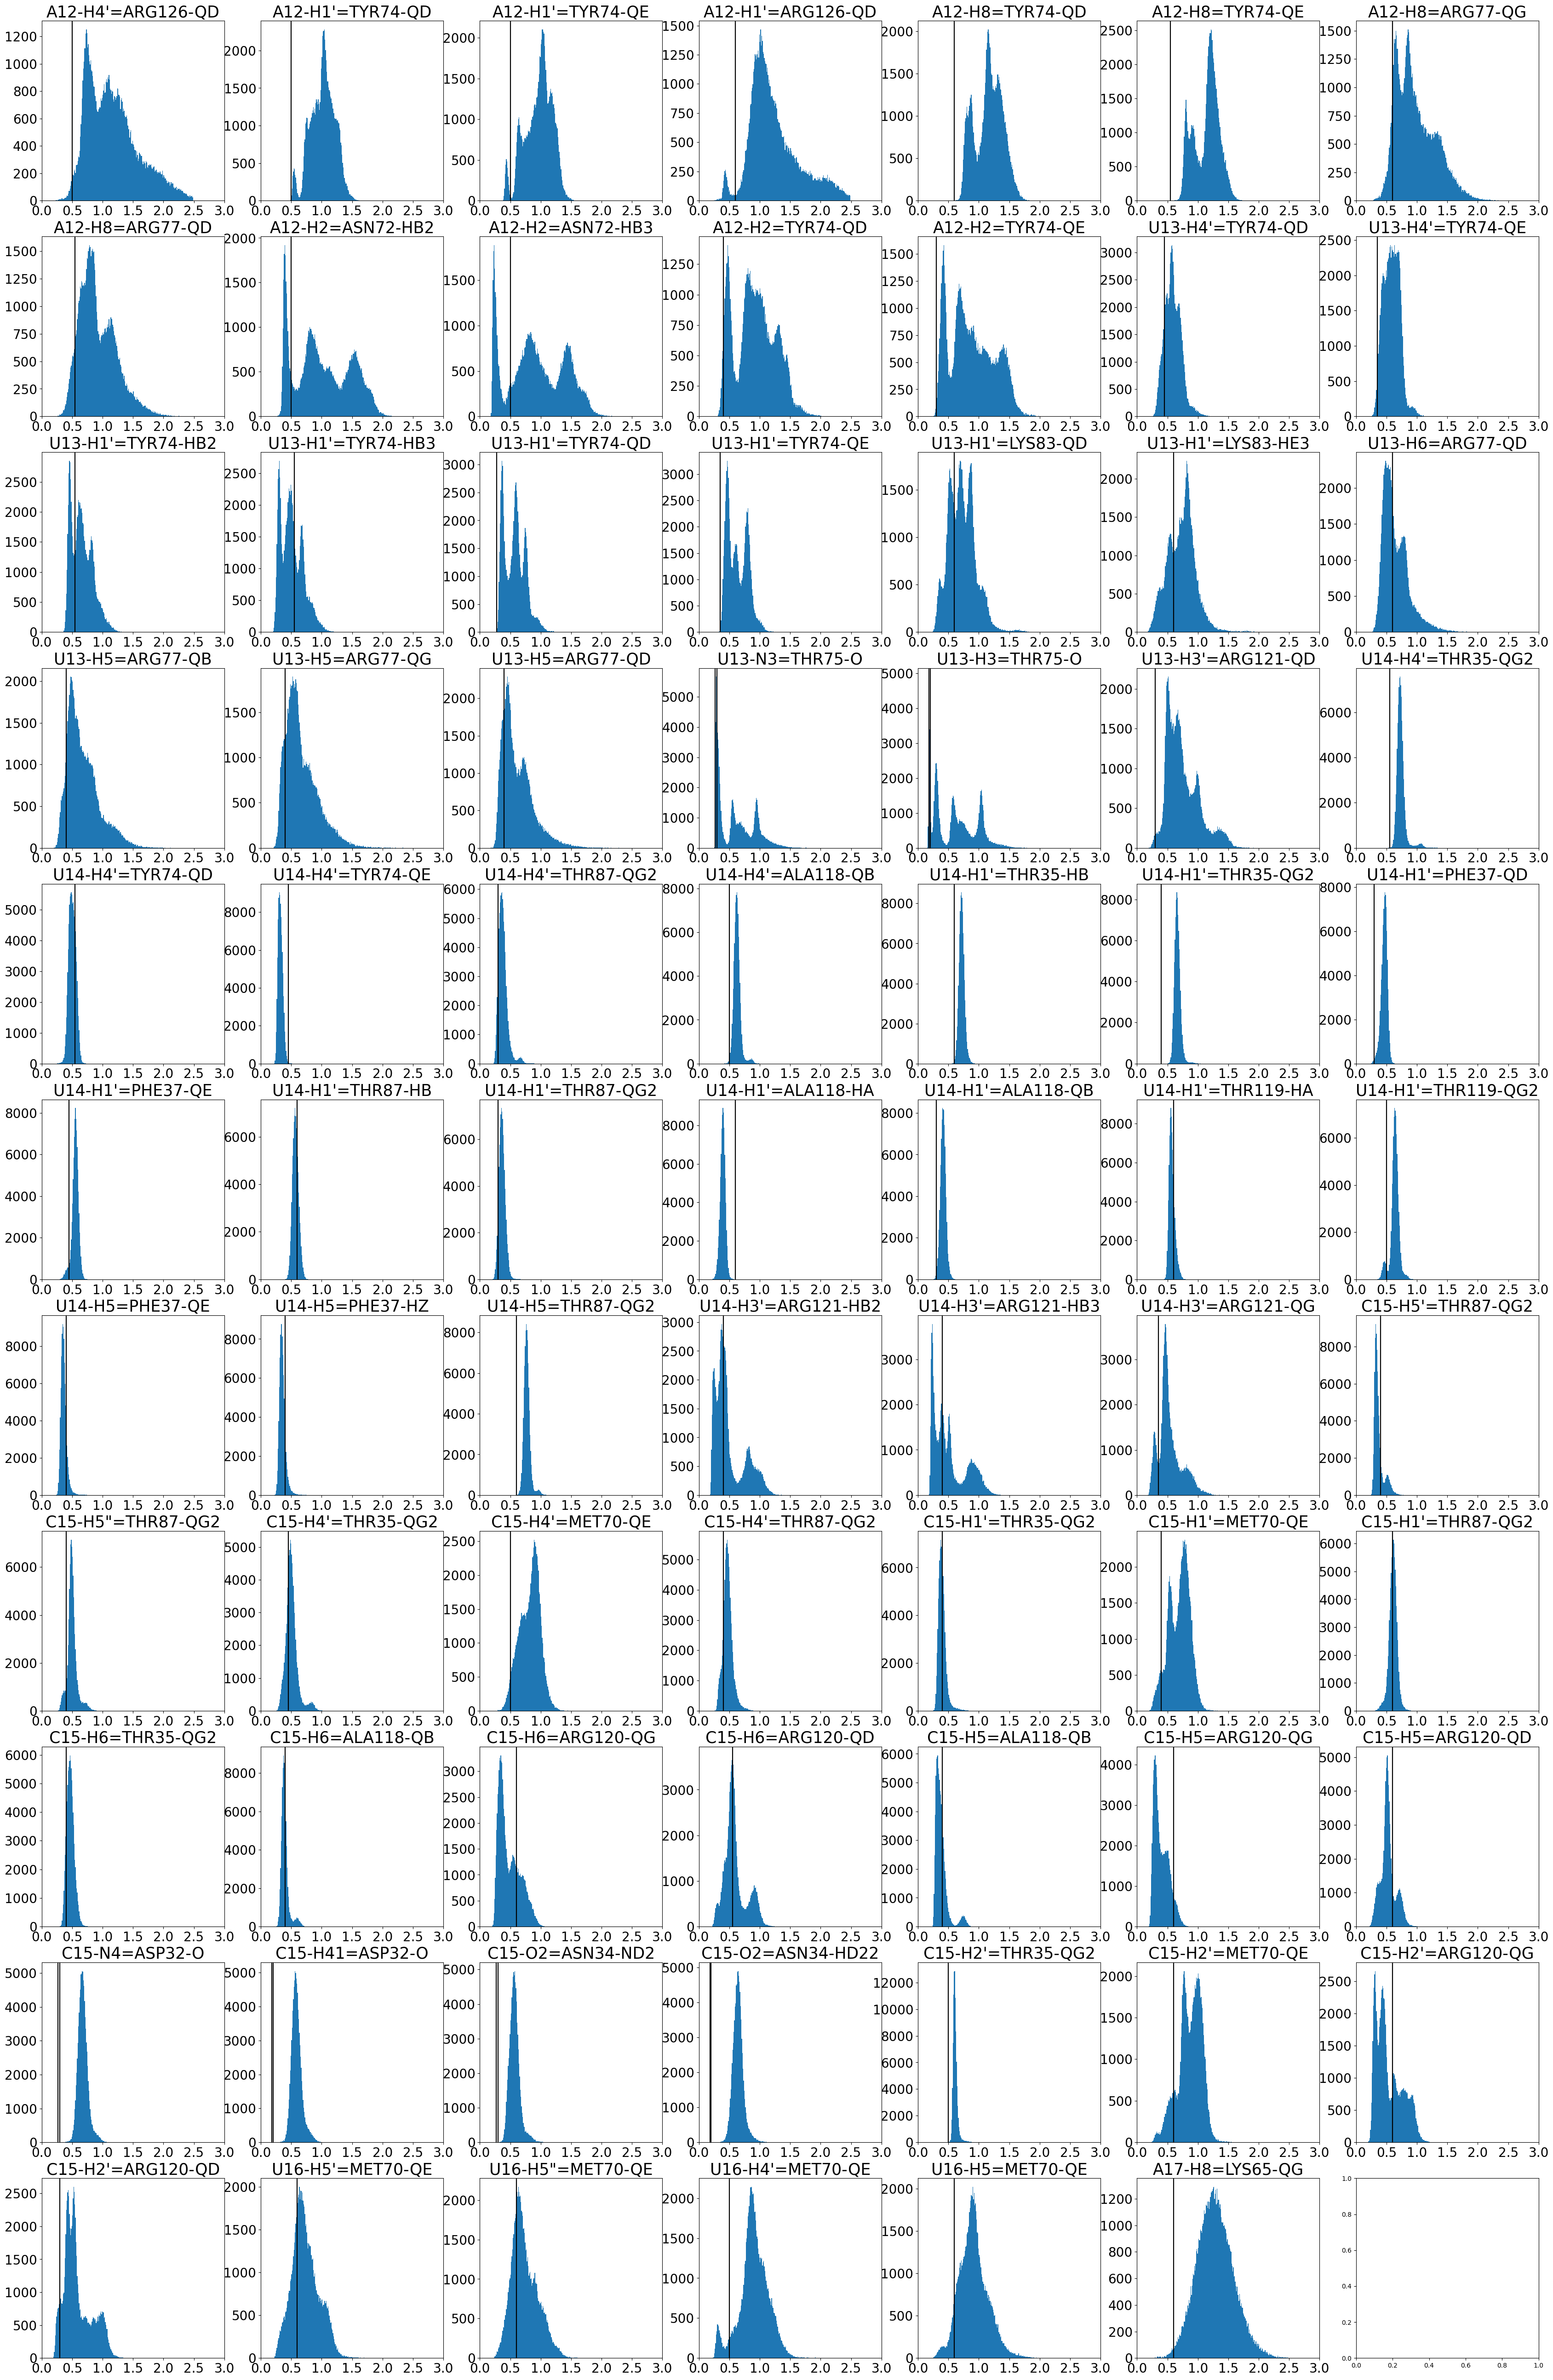

In [6]:
fig, ax = plt.subplots(11, 7)
fig.set_size_inches(42, 66)

i_restraint = 0
for atom_indices_0, atom_indices_1, distance_lower, distance_upper, residue_index_0, atom_name_0, residue_index_1, atom_name_1 in restraints:
    if (0 <= atom_indices_0[0] <= 727 and 734 <= atom_indices_1[0] <= 2295) or (734 <= atom_indices_0[0] <= 2295 and 0 <= atom_indices_1[0] <= 727):
        coms_0 = xtcs_all.atom_slice(atom_indices_0).xyz.mean(axis=1)
        coms_1 = xtcs_all.atom_slice(atom_indices_1).xyz.mean(axis=1)
        distances = np.linalg.norm(coms_0-coms_1, axis=1)

        ax[i_restraint//7, i_restraint%7].hist(distances, bins=[i*0.01 for i in range(250)])
        ax[i_restraint//7, i_restraint%7].axvline(distance_lower, color="black")
        ax[i_restraint//7, i_restraint%7].axvline(distance_upper, color="black")
        ax[i_restraint//7, i_restraint%7].set_title(f"{gleap_target.topology.residue(residue_index_0)}-{atom_name_0}={gleap_target.topology.residue(residue_index_1)}-{atom_name_1}", size=25)
        ax[i_restraint//7, i_restraint%7].set_xlim(0, 3)
        ax[i_restraint//7, i_restraint%7].set_xticks([0, 0.5, 1, 1.5, 2, 2.5, 3])
        ax[i_restraint//7, i_restraint%7].tick_params(axis='x', labelsize=20)
        ax[i_restraint//7, i_restraint%7].tick_params(axis='y', labelsize=20)

        i_restraint += 1

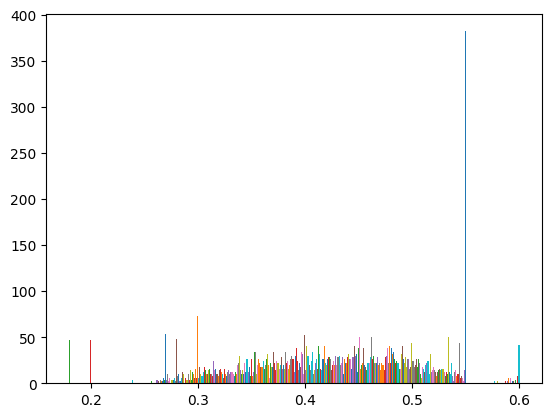

In [7]:
restraint_distances = {}
for atom_indices_0, atom_indices_1, distance_lower, distance_upper, residue_index_0, atom_name_0, residue_index_1, atom_name_1 in restraints:
    if not distance_lower in restraint_distances:
        restraint_distances[distance_lower] = 0
    restraint_distances[distance_lower] += 1
    if not distance_upper in restraint_distances:
        restraint_distances[distance_upper] = 0
    restraint_distances[distance_upper] += 1

for distance, count in restraint_distances.items():
    plt.bar(distance, count, width=0.001)